### **Introduction**
As an organisation, the United Nations (UN) aims to maintain international peace and security, foster friendly relations among nations, and promote cooperation in solving global challenges. However, the effectiveness of the UN remains mixed. While it has been instrumental in raising global challenges, its role as a neutral decision-making platform has been shaped by the differing interests and influence of its member states. Particularly, the Cold War (1947–1991) marked one of the most pivotal periods for the UN. As global politics became defined by ideological confrontation between the United States (US) and the Soviet Union (USSR), many countries found themselves situated within an intensely polarised UN. This period also saw the emergence of newly independent states from decolonisation, whose votes introduced new dynamics and shifted the balance of global influence. Hence, each member state’s vote reflected broader considerations on strategic alignments and alliances within a bipolar world order. 

This leads us to the key research question of this project – how did patterns of geopolitical alignment evolve during the Cold War as reflected by the voting dynamics in the UN General Assembly (UNGA)? To explore this in greater detail, this project examines how patterns of geopolitical alignment evolved in UNGA voting during the Cold War, through analysing the UN Votes dataset and implementing visualisations that illustrate (1) **change in global interest on various issues** (colonialism, economic development, etc.), (2) **each country’s alignment with the United States and the Soviet Union**, and (3) **different countries’ alignment with the majority vote for each issue**. Through these visualisations, we aim to trace not only how the Cold War shaped UN decision-making, but also how smaller nations navigated between the rival spheres of influence. The following sections outline our data cleaning and analytical processes, followed by three key visualisations that reveal the global political landscape of the Cold War era.

In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
from plotly.subplots import make_subplots
import plotly.graph_objects as go
import geopandas as gpd
import json
import plotly.io as pio

### Keep Visualisations Interactive in HTML ###
#pio.renderers.default = 'vscode' # comment when saving html
#pio.renderers.default = 'iframe'  # uncomment when saving html 
pio.renderers.default = 'notebook_connected'

sns.set_theme(style = 'darkgrid')

### read data in ###
issues = pd.read_csv('https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2021/2021-03-23/issues.csv', index_col = 0)
roll_calls = pd.read_csv('https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2021/2021-03-23/roll_calls.csv', index_col = 0, na_values=['NA', ''])
unvotes = pd.read_csv('https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2021/2021-03-23/unvotes.csv', index_col = 0)

issues = issues.reset_index(drop=False)

roll_calls = roll_calls.reset_index(drop=False)

unvotes = unvotes.reset_index(drop=False)

### **Data Cleaning & Exploratory Data Analysis**
The dataset used for this project combines three key sources from the UN General Assembly Voting Data Repository. 
**issues** matches 5745 non-unique rcids with one of 6 issues: Human Rights, Economic Development, Colonialism, the Palestinian Conflict, Disarmament, Nuclear. This means that some rcids have multiple issues associated with them. Also, some rcids do not have an issue assigned to them. We modified the issues dataset by dropping the issue column, and replacing the values in the short_name column with a mapping that replaces the unintuitive two-letter code with an intuitive name for each issue. This modification was done purely for ease of manipulation – for instance, we would rather type “Palestine” instead of “Palestinian Conflict” repeatedly. In general, we found that Disarmament, the Palestinian Conflict and Human Rights were the most discussed issues, at slightly over 1000 rcids associated with them. Economic Development surprisingly received the least attention, with only 765 rcids associated with it.  

**unvotes** provides a 869937-row record of how each country (present for voting) voted on a particular vote (represented by a rcid). Countries may choose to vote either “yes”, “no”, or “abstain”. We standardised the country_code naming for Czechoslovakia, Yugoslavia, German Democratic Republic and Yemen People’s Republic as well as the country naming for Federal Republic of Germany. Additionally, we identified that Yemen Arab Republic, Zanzibar, Federal Republic of Germany and Namibia did not have a corresponding country_code – we assigned them their relevant two-letter country codes. We found two interesting observations. The first was that “yes” votes outnumbered “abstain” and “no” votes by a factor of roughly 6:1 and 11:1. The second was that the United States and Israel were the countries that voted ‘no’ the most often – the United States voted ‘no’ as often as it voted ‘yes’ and ‘abstain’. 

**roll_calls** provides a variety of metadata associated with each vote, such as resolution number, session number, whether it’s an important vote, and descriptions on each vote. We know contextually that amend and para were coded only until 1985. unvotes was therefore split into two DataFrames, pre_1985 and post_1985, with the amend and para columns dropped in post_1985. Missing values remained in the unres, importantvote, short and descr columns, but we decided to leave them as they were as they did not affect our data analysis in any way. 


In [2]:
### data checks: issues ###

"""
rcid is a specific vote session id. 
this table maps the specific topic discussed to a specific vote session id.
"""
# print("shape: " + str(issues.shape)) #(5745, 3)
# print(issues.describe())
# print(issues.dtypes)
# print(issues.isna().sum()) # no NaN values
# print(issues.duplicated(subset=['rcid', 'short_name']).sum()) # no duplicates on rcid and short_name
# print(issues['short_name'].unique()) # ['me' 'nu' 'di' 'hr' 'co' 'ec']

map_issues = {'me': 'Palestine', 'nu': 'Nuclear', 'di': 'Arms', 'hr': 'Human Rights', 'co': 'Colonialism', 'ec': 'Economic Development'}
issues['short_name'] = issues['short_name'].replace(map_issues)
issues = issues.drop(columns=['issue']).sort_values('rcid') 


#Exploratory Data Analysis
print(issues['short_name'].unique())
summary_issues = issues.groupby('short_name').count().sort_values('rcid', ascending=False)
print(summary_issues)

### Note: some rcids don't have issue tags (i.e not in this dataset), some have multiple.

['Human Rights' 'Economic Development' 'Colonialism' 'Palestine' 'Arms'
 'Nuclear']
                      rcid
short_name                
Arms                  1092
Palestine             1061
Human Rights          1015
Colonialism            957
Nuclear                855
Economic Development   765


In [3]:
### data checks: unvotes ###

"""
this table describes how each country voted in each voting session. 
"""

# print("shape: " + str(unvotes.shape)) #(869937, 4)
# print(unvotes.describe())
# print(unvotes.dtypes) 
# print(unvotes.isna().sum()) #country code has 7898 missing values 

missing_country = unvotes[unvotes['country_code'].isna()]

### update country codes (present in data cleaning steps on GitHub, written in R) ###
unvotes['country_code'] = np.where(unvotes['country'] == 'Czechoslovakia', 'CS', unvotes['country_code'])
unvotes['country_code'] = np.where(unvotes['country'] == 'Yugoslavia', 'YU', unvotes['country_code'])
unvotes['country_code'] = np.where(unvotes['country'] == 'German Democratic Republic', 'DD', unvotes['country_code'])
unvotes['country_code'] = np.where(unvotes['country'] == "Yemen People's Republic", 'YD', unvotes['country_code'])

unvotes['country'] = np.where(
    (unvotes['country'].notna()) & (unvotes['country'] == "German Federal Republic"),
    "Federal Republic of Germany",
    unvotes['country']
)

### attach country codes to countries without country codes ###

# print(missing_country['country'].unique()) #['Yemen Arab Republic' 'Zanzibar' 'Federal Republic of Germany' 'Namibia']
mapping = {'Yemen Arab Republic': 'YA', 'Zanzibar': 'ZN', 'Federal Republic of Germany': 'WG', 'Namibia': 'NA'}
unvotes['country_code'] = unvotes['country_code'].fillna(unvotes['country'].map(mapping))

# print(unvotes.isna().sum()) # now country code has no missing values
# print(unvotes.duplicated(subset=['rcid', 'country_code']).sum()) # on rcid and country_code, no duplicates

### Exploratory Data Analysis ###

#Find proportion of yes, no, abstain votes across all votes
summary_vote = unvotes.groupby('vote').size()
print(summary_vote)

### Find the top few countries likely to vote yes, no and abstain ###

yes_proportion = pd.DataFrame()
no_proportion = pd.DataFrame()
abstain_proportion = pd.DataFrame()
countries = unvotes['country'].unique()
for country in countries: 
    subset = unvotes[unvotes['country'] == country]
    yes = round(subset[subset['vote'] == 'yes'].shape[0] / subset.shape[0], 2)
    no = round(subset[subset['vote'] == 'no'].shape[0] / subset.shape[0], 2)
    abstain = round(subset[subset['vote'] == 'abstain'].shape[0] / subset.shape[0], 2)

    yes_df = pd.DataFrame({'country': [country], 'proportion': [yes]})
    yes_proportion = pd.concat([yes_proportion, yes_df], axis = 0)
    no_df = pd.DataFrame({'country': [country], 'proportion': [no]})
    no_proportion = pd.concat([no_proportion, no_df], axis = 0)
    abstain_df = pd.DataFrame({'country': [country], 'proportion': [abstain]})
    abstain_proportion = pd.concat([abstain_proportion, abstain_df], axis = 0)

for vote, df in [("yes", yes_proportion), ("no", no_proportion), ("abstain", abstain_proportion)]: 
    df = df.sort_values('proportion', ascending = False)
    print(f"Top 3 countries likely to vote {vote}")
    print(df.head(3))

vote
abstain    110893
no          65500
yes        693544
dtype: int64
Top 3 countries likely to vote yes
               country  proportion
0           Seychelles        0.98
0  São Tomé & Príncipe        0.96
0          Timor-Leste        0.95
Top 3 countries likely to vote no
         country  proportion
0  United States        0.50
0         Israel        0.39
0          Palau        0.38
Top 3 countries likely to vote abstain
                       country  proportion
0                     Zanzibar        1.00
0  Federal Republic of Germany        0.42
0                  South Sudan        0.36


In [4]:
### data checks: roll_calls ###

"""
this table describes the details of each vote: date, resolution number, descriptions of what the vote is about.
"""

# print(roll_calls.head(1))
# print("shape: " + str(roll_calls.shape)) #(6202, 9)
# print(roll_calls.describe()) #5598/6164 important votes (of those assessed); 2868 amendment votes, 3208 paragraph votes
# print(roll_calls.duplicated(subset=['rcid']).sum()) #no duplicates
# print(roll_calls.isna().sum()) 

"""
missing values: 
importantvote     604
unres             159
amend            3334
para             2994
short             573
descr               1
"""

# print(roll_calls.dtypes) #convert date to DateTime
roll_calls['date'] = pd.to_datetime(roll_calls['date'], format='%Y-%m-%d')
# print(roll_calls.dtypes)

pre_1985 = roll_calls[roll_calls['date'].between('1946-01-01', '1984-12-31')].sort_values('date', ascending=True)
# print(pre_1985.shape[0]) #2844
# print(pre_1985.isna().sum()) #all cleaned except for 151 missing entries for unres

""" 
missing values:
rcid               0
session            0
importantvote      0
date               0
unres            151
amend              0
para               0
short              0
descr              0
"""

post_1985 = roll_calls[roll_calls['date'].between('1985-01-01', '2020-01-01')].sort_values('date', ascending=True)
post_1985 = post_1985.drop(columns=['amend', 'para'])
# print(post_1985.head(1))
# print(post_1985.isna().sum()) #missing entries: 604 importantvote, 8 unres, 573 short, 1 descr

"""
rcid               0
session            0
importantvote    604
date               0
unres              8
short            573
descr              1
"""

pre_no_amend_para = pre_1985[['rcid', 'session', 'importantvote', 'date', 'unres', 'short', 'descr']]
roll_calls_no_amend_para = pd.concat([pre_no_amend_para, post_1985], axis=0)
# print(roll_calls_no_amend_para.shape) #(6202,7) 
# print(roll_calls_no_amend_para.isna().sum()) #missing entries: 604 importantvote, 159 unres, 573 short, 1 descr

___

## Visualisation 1: **Shifting Global Priorities in the United Nations during the Cold War**

Before we can begin to analyse alignment, we first have to determine what issues the countries are aligning themselves on in the first place. Hence, we wanted to observe the trends of issues in the UNGA agenda during the Cold War. In the figure above, we illustrated the proportion of each issue in the UNGA throughout the Cold War. This reflects the most pressing global priorities because a higher proportion would mean that more countries are raising these issues to the UNGA’s agenda.  A scatter plot was used with a line connecting the points because the data represents a time series of how the share of votes for each issue evolved across the span of the cold war. In our plot, each data point represents the proportion of resolutions that fell under a specific issue for that particular 5 year period. Thus, we are able to observe the trend across time as well as relative prominence of issues. 
The formula used for proportion of an issue is: 
$$ \text{Proportion of vote} = \frac{\text{Count of votes for an issue in a period}}{\text{Total count of votes for that period}} $$

### *Data Manipulation*
For this visualisation, only the roll calls metadata and the issues categories were merged on the vote session identifier (rcid). This produced a dataset where each resolution was linked to its associate issue category, resulting in a dataframe shape of (7848, 8).  The dataset was then filtered to focus exclusively on the Cold War period (1947-1991). To analyse trends over time, a new column for the year of each resolution was created. Resolutions were grouped into 5-year periods using pd.cut. Labels such as “1947-1951” were generated to represent each 5-year period. Next, the data was aggregated to compute the number of resolutions per issue area in each 5-year period. This was followed by calculating the total number of resolutions per period, which allowed us to compute the share of resolutions per issue within each period. For clarity in plotting, a new column, period_start, was created to extract only the starting year of each period.  Finally, for visualisation, issues of particular interest (disarmament and nuclear weapons) were highlighted using thicker lines and higher transparency (alpha = 1.0). All other issues were displayed with lower transparency (alpha = 0.3). This allowed trends for Cold War issues to stand out from the other issue areas. 



/var/folders/3k/f7hjjv9x7tsc4ndc4kgz22y40000gn/T/ipykernel_30561/1862573445.py:15: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.

/var/folders/3k/f7hjjv9x7tsc4ndc4kgz22y40000gn/T/ipykernel_30561/1862573445.py:19: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



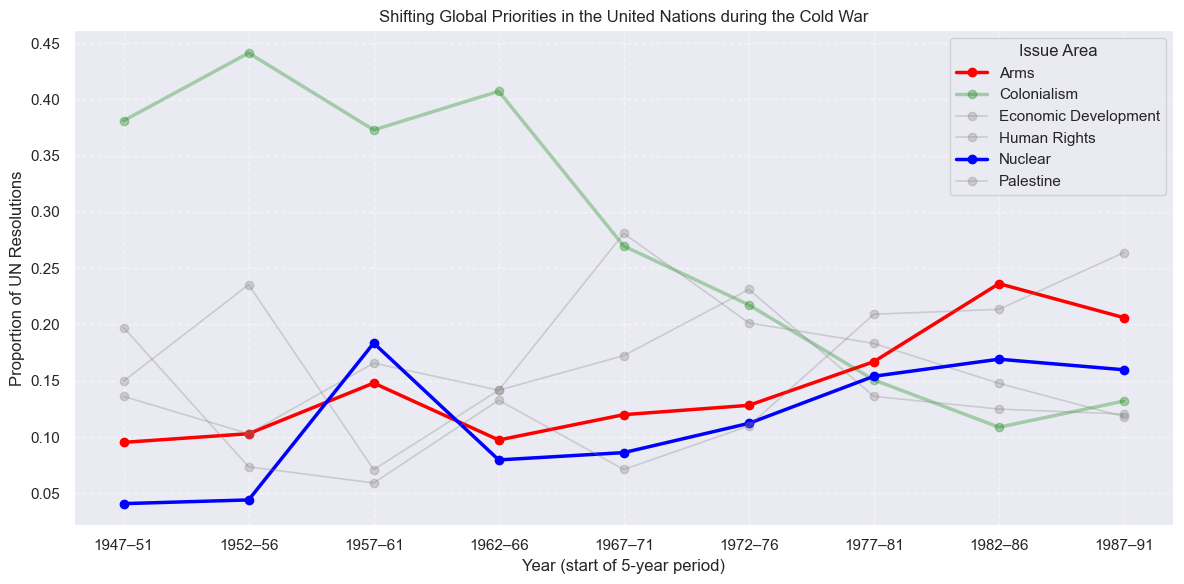

In [5]:
### Question: What is the trend of issues in the UNGA agenda during the Cold War ###
merged_vis1 = pd.merge(roll_calls_no_amend_para, issues[['rcid', 'short_name']], on = 'rcid', how = 'left')

# print(merged_vis1.shape) # (7848, 8)
# print(merged_vis1['short_name'].value_counts())

cold_war = merged_vis1.query("'1947-03-12' <= date <= '1991-12-26'").copy() # focus on cold war period, dates from chatGPT

bins = list(range(1947, 1997, 5)) # get groups of 5 years 
labels = [f"{y}-{y+4}" for y in bins[:-1]] # get labels corersponding to this list of 5 years 
cold_war['year'] = cold_war['date'].dt.year # new column for the year 
cold_war['period'] = pd.cut(cold_war['year'], bins=bins, labels=labels, right=True) # assigning to each 5 year period

issue_trends = (
    cold_war.groupby(['period', 'short_name'])
    .size()
    .reset_index(name='count')
)
issue_trends['total_per_period'] = issue_trends.groupby('period')['count'].transform('sum') # count per period 
issue_trends['share'] = issue_trends['count'] / issue_trends['total_per_period'] # proportion of period 
issue_trends['period_start'] = issue_trends['period'].apply(
    lambda x: f"{str(x)[:4]}–{str(x)[7:9]}" if pd.notna(x) else x
) # x axis labels

plt.figure(figsize=(12,6)) # needs to be before the plot arg
highlighted_issues = ["Arms", "Nuclear"]
highlighted_alpha = 1.0 # for highlighted issues
other_alpha = 0.3 # for others

for issue, data in issue_trends.groupby('short_name'):
    if issue in highlighted_issues:
        colour = 'red' if issue == 'Arms' else 'blue'
        plt.plot(data['period_start'], data['share'], marker='o', label=issue, alpha = highlighted_alpha, linewidth = 2.5, color = colour)
    else:
        if issue == 'Colonialism':
            plt.plot(data['period_start'], data['share'], marker='o', label=issue, alpha = other_alpha, linewidth = 2.5, color = 'green')
        else:
            plt.plot(data['period_start'], data['share'], marker='o', label=issue, alpha = other_alpha, linewidth = 1.2, color = 'grey')

ax = plt.gca()
for i in ["bottom", "left", "top", "right"]:
    ax.spines[i].set_linewidth(1.5)
plt.title("Shifting Global Priorities in the United Nations during the Cold War")
plt.xlabel("Year (start of 5-year period)")
plt.ylabel("Proportion of UN Resolutions")
plt.legend(title="Issue Area")
plt.xticks(sorted(issue_trends['period_start'].unique()))  # show start years only
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

### *Findings & Interpretation*
From the visualisation, Arms control and Disarmament (di) and Nuclear weapons and material (nu) were the least prominent issues in UN resolutions at the start of the cold war. However, throughout the duration of the Cold War, the proportion of resolutions devoted to these two issues steadily increased, reflecting growing international concern over development of nuclear weaponry and military capability. By early 1980, di and nu had become the second and third most frequently raised issues, highlighting the central role of arms control and nuclear diplomacy in global politics. This reflects the changing priorities of members under the influence of Cold War dynamics. 

___

## Visualisation 2: **Global Political Alignment with the US and USSR during the Cold War**
Being the two superpowers during the Cold War, we decided to visualise global political alignment with the US and USSR respectively using an interactive choropleth map. The maps illustrate how each country’s voting behaviour in the UN General Assembly aligned with the US (left) and the USSR (right) on resolutions concerning arms control and nuclear disarmament between 1947 and 1991. A choropleth map is ideal for this analysis as it highlights spatial and geopolitical patterns that are not easily observable in other chart types, revealing how ideological divisions were geographically distributed across regions.

### *Data Manipulation*
A new column variable (‘align_us’, ‘align_ru’) was created which showed the US and USSR’s stance on each vote, allowing easy comparison with the other countries. To measure alignment, the alignment proportion for each country was calculated as the average share of resolutions where its vote (Yes, No, or Abstain) matched that of the US or USSR. The inclusion of abstentions ensures that neutrality and non-participation were captured as part of a country’s overall voting behaviour, since abstention often represented an intentional political stance rather than disengagement. We then used ‘country_code’ to map each alignment score onto the choropleth map to avoid. The colorbar scale beside each plot ranges from Low (0.00–0.33) to Neutral (around 0.50) and High (0.67–1.00), where values represent the proportion of voting agreement between each country and the respective superpower. This configuration effectively distinguishes countries strongly aligned with either bloc from those maintaining a neutral stance.



In [6]:
### Question: How did voting patterns vary across geographic regions during the Cold War? ###

# Merge all 3 datasets
merged_vis2 = (
    unvotes
    .merge(roll_calls_no_amend_para, on='rcid', how='left')
    .merge(issues, on='rcid', how='left')
)
# Keep relevant columns
merged_vis2 = merged_vis2[['rcid', 'country', 'country_code', 'vote', 'date', 'short_name']]

# Filter for Cold War Period
merged_vis2 = merged_vis2[merged_vis2['date'].between('1947-03-12', '1991-12-26')].copy()

# Filter for Arms & Nuclear issues only
merged_vis2 = merged_vis2[merged_vis2['short_name'].isin(['Arms', 'Nuclear'])]

In [7]:
# Create reference vote columns for US and Russia
us_votes = merged_vis2[merged_vis2['country'] == 'United States'][['rcid', 'vote']].rename(columns={'vote': 'us_vote'})
ru_votes = merged_vis2[merged_vis2['country'].isin(['Russia', 'Soviet Union'])][['rcid', 'vote']].rename(columns={'vote': 'ru_vote'})

# Merge the reference votes for US and Russia
alignment = (
    merged_vis2
    .merge(us_votes, on='rcid', how='left')
    .merge(ru_votes, on='rcid', how='left')
)
# Remove NA values
alignment = alignment.dropna(subset=['us_vote', 'ru_vote'])

# Compute alignment with each session
alignment['align_us'] = (alignment['vote'] == alignment['us_vote']).astype(int)
alignment['align_ru'] = (alignment['vote'] == alignment['ru_vote']).astype(int)

# Compute the alignment score
alignment_score = (
    alignment.groupby(['country', 'country_code'], as_index=False)[['align_us', 'align_ru']]
    .mean()
    .sort_values('align_us', ascending=False)
)


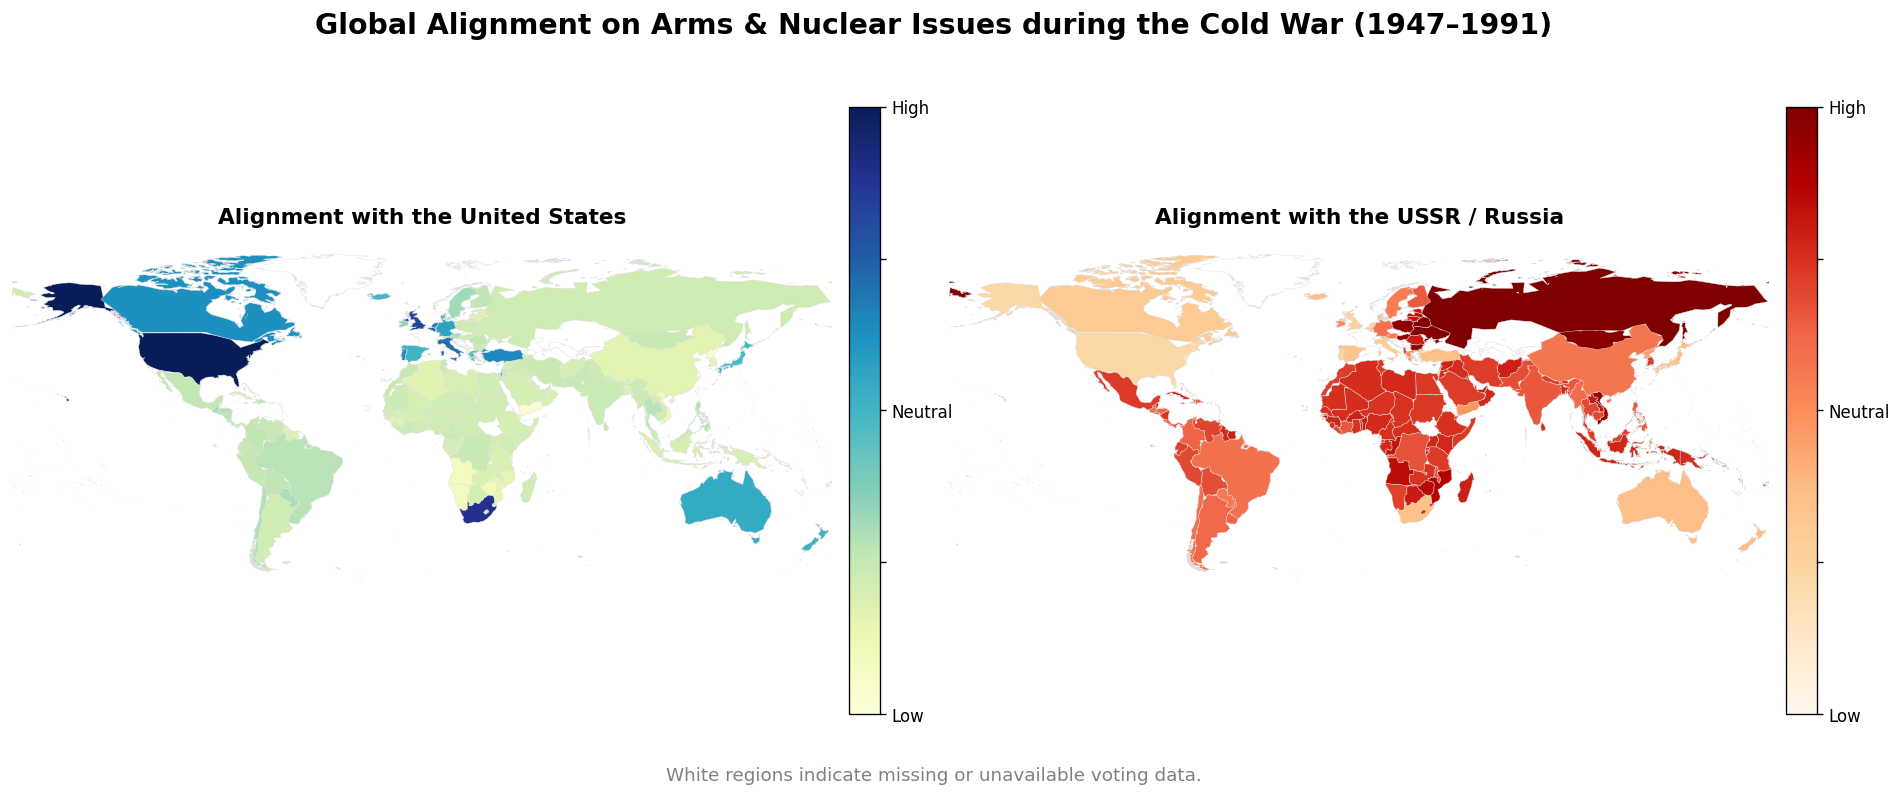

In [8]:
# Use Natural Earth's lower-resolution boundaries and Matplotlib so this
# visualisation remains compact and is rendered directly by GitHub.
world = gpd.read_file(
    "https://naciscdn.org/naturalearth/110m/cultural/ne_110m_admin_0_countries.zip"
)
world = world.merge(alignment_score, left_on="ISO_A2", right_on="country_code", how="left")

fig, axes = plt.subplots(1, 2, figsize=(16, 7), facecolor="white")

def plot_alignment(ax, column, cmap, title):
    ax.set_facecolor("#A8CBE2")
    world.plot(
        column=column,
        cmap=cmap,
        vmin=0,
        vmax=1,
        ax=ax,
        edgecolor="#E0E0E0",
        linewidth=0.35,
        missing_kwds={"color": "white", "edgecolor": "#E0E0E0"},
    )
    ax.set(xlim=(-180, 180), ylim=(-60, 90))
    ax.set_axis_off()
    ax.set_title(title, fontsize=13, fontweight="bold", pad=10)

    scale = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(0, 1))
    scale.set_array([])
    colorbar = fig.colorbar(
        scale, ax=ax, fraction=0.035, pad=0.02, ticks=[0, 0.25, 0.5, 0.75, 1]
    )
    colorbar.ax.set_yticklabels(["Low", "", "Neutral", "", "High"])

plot_alignment(axes[0], "align_us", "YlGnBu", "Alignment with the United States")
plot_alignment(axes[1], "align_ru", "OrRd", "Alignment with the USSR / Russia")

fig.suptitle(
    "Global Alignment on Arms & Nuclear Issues during the Cold War (1947–1991)",
    fontsize=17,
    fontweight="bold",
    y=0.95,
)
fig.text(
    0.5,
    0.035,
    "White regions indicate missing or unavailable voting data.",
    ha="center",
    color="gray",
    fontsize=11,
)
fig.subplots_adjust(left=0.02, right=0.96, top=0.86, bottom=0.09, wspace=0.08)
plt.show()


### *Findings & Interpretation*
From the visualisation, a clear bipolar division emerges, reflecting the ideological tensions that defined international politics during the Cold War. The Western bloc (i.e. Canada, Western Europe, Japan, Australia, and South Africa) shows strong alignment with the US, mirroring post-war alliances such as NATO and the broader network of capitalist democracies. Conversely, the Eastern bloc, comprising the USSR and its allied states across Eastern Europe and Central Asia, exhibits high alignment with the Soviet Union through institutions like the Warsaw Pact and COMECON. In contrast, much of Africa, the Middle East, and Southeast Asia appear in neutral tones, representing members of the Non-Aligned Movement (NAM) that sought to remain outside the Cold War binary, though they appear to be more aligned to the USSR as compared to the US, being more red than blue. Overall, the maps capture how the East–West divide extended beyond military and economic blocs into the political decision-making processes of the UN, shaping international consensus on key issues of peace and security.

___

## Visualisation 3: **Country-Specific Alignment with the Majority in the United Nations**

Another way to determine broad geopolitical alignment is to see how aligned a global power’s vote is with the majority. If so, this suggests that it is more united with the majority, or it has greater influence over them, such that many countries choose to follow the superpower’s vote until its vote ends up being the majority vote. Should countries not be aligned with global powers, analysing alignment with the majority vote would also reveal – beyond the traditional US & Soviet Union factions – insights into other underlying trends and groups shaping majority opinion in the United Nations. 

### *Data Manipulation*
A correlation score was thus developed to assess this alignment. For each vote (rcid) in the unvotes dataset, we first assigned a majority result (yes, no, abstain), indicating what the greatest proportion of countries voted for on this vote – this was assigned to a newly created majority column. A correlation metric was defined, where we assigned a score of 1 for situations where “(country votes x, majority votes x) for x in [‘yes’, ‘no’, ‘abstain’]” and 0 otherwise. As we wanted to observe voting trends across the different issues, we created 6 bar plots, 1 bar plot for each issue. Bar plots were used because as we are comparing against countries which is a categorical variable and it allows us to compare the scores. Within each bar plot, we included 3 countries with the highest correlation score for these issues, as well as that of our identified countries of interest. To do so, we first had to merge the issues that correspond to each rcid onto the unvotes dataset with the correlation score.

In [9]:
### Question: Do countries vote with the majority and/or follow global powers? ###

# update timeframe: 1947-1991
rollcall_cold_war = roll_calls[roll_calls['date'].between('1947-03-12', '1991-12-26')]['rcid']
unvotes = unvotes[unvotes['rcid'].isin(rollcall_cold_war)]

# update unvotes with a column on whether the vote passed or failed
yes_ratio = ((unvotes['vote'] == 'yes').groupby(unvotes['rcid']).mean()).rename('yes') 
no_ratio = ((unvotes['vote'] == 'no').groupby(unvotes['rcid']).mean()).rename('no')
abstain_ratio = ((unvotes['vote'] == 'abstain').groupby(unvotes['rcid']).mean()).rename('abstain')
ratio = pd.concat([yes_ratio, no_ratio, abstain_ratio], axis = 1) #combine horizontally 
unvotes['majority'] = unvotes['rcid'].map(ratio.idxmax(axis=1)) #returns corresponding index with highest value

# merge with short_name column on issues df
correlated = ((unvotes['vote'] == 'yes') & (unvotes['majority'] == 'yes') |
                           (unvotes['vote'] == 'no') & (unvotes['majority'] == 'no') |
                           (unvotes['vote'] == 'abstain') & (unvotes['majority'] == 'abstain')) #returns a Boolean series for each row

# obtain correlation score by country across all issues, across all time
correlation_table = correlated.groupby(unvotes['country']).mean().reset_index(drop=False).rename(columns={0: 'correlation_score'}).sort_values('correlation_score', ascending=False)
correlation_table['correlation_score'] = round(correlation_table['correlation_score'], 2)
correlation_table = correlation_table.reset_index(drop=True)
print(f"Number of countries: {len(correlation_table)}")

countries_of_interest = ['United States', 'China', 'United Kingdom', 'Russia', 'France', 'Singapore']
first_entry = correlation_table.head(3)
filtered_table = correlation_table[correlation_table['country'].isin(countries_of_interest)]
filtered_table_with_first = pd.concat([first_entry, filtered_table], axis = 0)

print(filtered_table_with_first)

Number of countries: 172
            country  correlation_score
0           Vanuatu               0.98
1           Namibia               0.97
2          Djibouti               0.97
60            China               0.89
75        Singapore               0.88
140          Russia               0.68
167  United Kingdom               0.42
168          France               0.42
170   United States               0.36


In [10]:
# find the rcids for each issue 
unvotes['correlated'] = correlated
unvotes_issues = unvotes.merge(issues, on = 'rcid', how = 'left')

# dataframe with columns: country, issue, score
country_corr_issues = unvotes_issues.groupby(['country', 'short_name'])[['correlated']].mean().sort_values(['short_name', 'correlated'], ascending = [True, False]).reset_index()

# subsetting countries of interest + top 3, but first removing new countries with <5 years in the UN in 1991

# removing new countries
rollcall_88_91 = roll_calls[roll_calls['date'].between('1988-01-01', '1991-12-26')]['rcid']
rollcall_47_87 = roll_calls[roll_calls['date'].between('1947-03-12', '1987-12-31')]['rcid']

countries_in_88_91 = set(unvotes[unvotes['rcid'].isin(rollcall_88_91)]['country'].unique())
countries_in_47_87 = set(unvotes[unvotes['rcid'].isin(rollcall_47_87)]['country'].unique())
new_countries = countries_in_88_91.difference(countries_in_47_87)
country_corr_issues = country_corr_issues[~(country_corr_issues['country'].isin(new_countries))]

# subsetting top 3 + countries of interest
country_corr_issues['rank'] = country_corr_issues.groupby('short_name')['correlated'].rank(method = 'first', ascending = False)
country_corr_issues = country_corr_issues[(country_corr_issues['rank'] <= 3) | (country_corr_issues['country'].isin(countries_of_interest))]

# making top 3 diff colour for plot
country_corr_issues['group'] = 'Countries of Interest'
country_corr_issues.loc[country_corr_issues['rank'] <= 3, 'group'] = 'Top 3'
# country_corr_issues

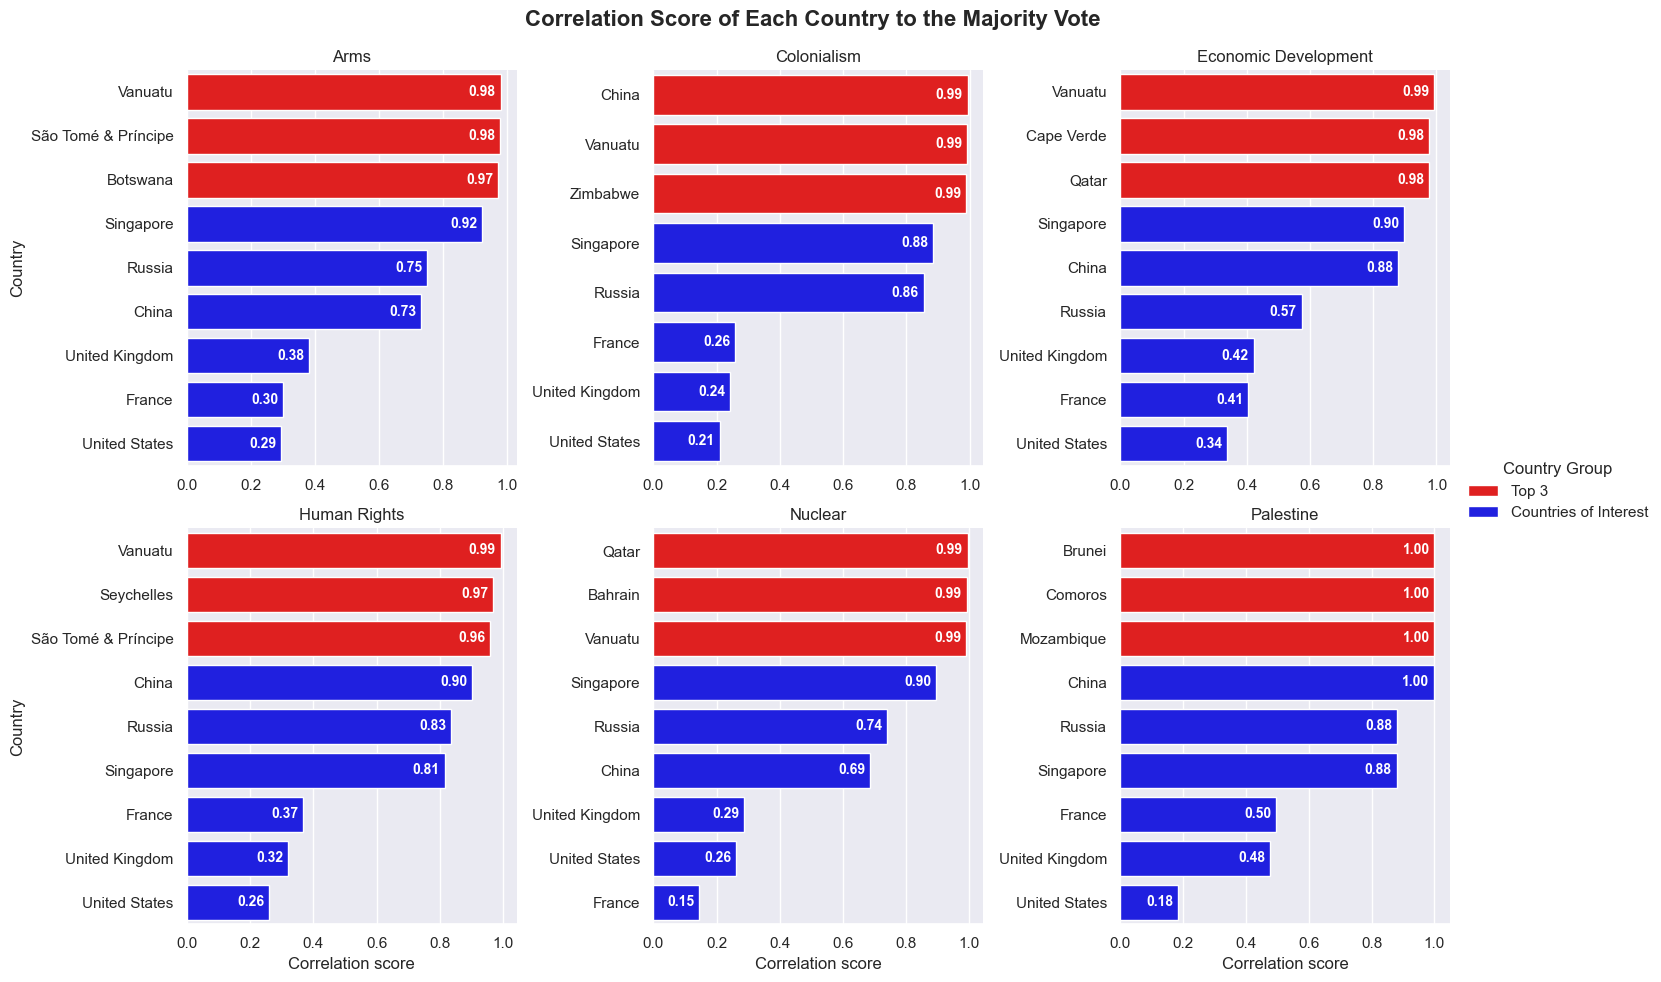

In [11]:
g = sns.catplot(country_corr_issues, kind = 'bar', 
                x = 'correlated', y = 'country', 
                col = 'short_name', col_wrap = 3, 
                sharex = False, sharey = False, hue = 'group', 
                palette = ['red', 'blue'], legend = True)
g.set_axis_labels('Correlation score', 'Country')
g.set_titles('{col_name}')
g.figure.suptitle('Correlation Score of Each Country to the Majority Vote', fontsize = 16, fontweight = 'bold')
g.figure.subplots_adjust(top = 0.92)
g.legend.set_title('Country Group')

for ax in g.axes.flat:
    for container in ax.containers:
        ax.bar_label(container, fmt='%.2f', fontsize = 10, weight = 'bold', label_type = 'edge', padding = -23, color = 'white')
        
plt.show()

### *Findings & Interpretation*
Across all 6 issues, it was clear that countries in the Western Bloc (United States, United Kingdom, France) had low correlation scores of < 0.5, meaning that they often voted against the majority, or that countries are not too concerned about aligning their vote with the global powers. The Soviet Union, interestingly, did not have a high correlation score either (~0.6), implying that its votes were not as consequential in determining global voting patterns. It was also evident that the top 3 countries for each issue were consistently small states (Vanuatu, São Tomé and Príncipe, Cape Verde). The higher scores of these countries, along with China and Singapore, can be explained by the existence of the Non-Aligned Movement (NAM). This voting bloc consisted of around 120 countries that did not align themselves geopolitically with the United States and the Soviet Union (many of which were small states), thereby shaping majority consensus. The low scores of countries within the Western Bloc (e.g United States, United Kingdom) – countries that continue to wield a disproportionate amount of soft power and influence – paint a picture of a powerful bloc, small in number, that often acts in opposition to the majority. The consequence of this is that many of these countries – which are neither strictly aligned with the US or Soviet Union (given the US and Soviet Union’s low correlation score) – suffer grievously from the actions of a few, including navigating a Cold War. We also note that for the 2 issues which rose to prominence, Arms control and Nuclear weapons, the difference in scores among the global powers is larger. Clearly, more work needs to be done to reach a consensus – disagreements remain sharp despite increased attention on these issues. 

___

## **Conclusion**
Taken together, our analyses reveal that voting dynamics in the UN General Assembly during the Cold War mirrored the broader geopolitical landscape of the era. The first visualisation demonstrated a gradual shift in global priorities as the Cold War progressed, as issues concerning arms control and nuclear disarmament gained prominence alongside the intensifying East–West rivalry. The second visualisation revealed some level of geopolitical bifurcation, with the Western and Eastern blocs voting closely with the United States and the Soviet Union, respectively, while newly independent and smaller states often occupied neutral ground within the Non-Aligned Movement. The third visualisation showed that major powers frequently diverged from the majority consensus, suggesting that smaller and non-aligned countries played a greater role in shaping global sentiment than the superpowers themselves. Overall, the findings indicate that while Cold War ideology deeply influenced UN decision-making, the growing participation of post-colonial states introduced a more multipolar and independent dimension to global politics.

___

## **Teamwork contribution**
The introduction and conclusion were jointly written by all members to ensure coherence and consistency in framing and addressing the research question. Timotheus Teng Da Hui led the data cleaning process and contributed to Visualisation 3 by developing the code and analysis together with Lee Chong Yih, Joseph. Loh Zheng Wei Caleb was responsible for the Visualisation 1 code and write-up, focusing on the shifting global priorities in the UN during the Cold War. Aloysius Chua Weiheng and Renee Lim Xin Ni jointly developed Visualisation 2 and its accompanying interpretation, highlighting global political alignment with the US and USSR. Throughout the project, the team worked collaboratively to integrate the visualisations, refine interpretations, and ensure that the analysis aligned with the overarching research question. 


## **References**
Çetinkaya-Rundel, M., Robinson, D., & Goguen-Compagnoni, N. (2021, March 23). UN votes – TidyTuesday dataset (Week 13, 2021) [Data set]. GitHub: rfordatascience/tidytuesday.
Retrieved from https://github.com/rfordatascience/tidytuesday/tree/main/data/2021/2021-03-23

The Non-Aligned Movement (NAM). (n.d.). https://www.mfa.gov.bn/Pages/The-Non-Aligned-Movement-(NAM)-.aspx